# Healthcare insurance cost analysis
Unit 1: Data Analytics and Python for Data Preparation

Prepared with OpenAI Codex assistance, 27 October 2026. This is an AI-assisted project draft. The student should review the code, wording and conclusions and be able to explain them before submission. No personal learning experience or independent authorship is claimed.

The aim is to understand differences in recorded insurance charges, rather than to decide what an individual should pay. The notebook follows Tasks 1-4 and identifies the assessment criteria. Figures use the source's numeric charge scale because its currency is not confirmed.

## Task 1: Business case (1.1 and 1.2)
### Applications of analytics in healthcare insurance (1.1)

**Cost comparison and resource planning.** A planning team can compare average charges and the spread of charges across groups to see where large expenses occur. For example, a manager might investigate why one area has higher recorded expenditure before changing the budget. AHRQ's HCUP programme brings together encounter-level data for research into cost, utilisation, access and outcomes [2]. A practical resource-planning analysis would need service dates, encounters, provider capacity and membership counts as well as money values. That would let a team compare demand per covered person and plan staffing or provider contracts. The benefit is a clearer basis for allocating resources. The limitation is that a higher charge may reflect prices, case mix or recording practices rather than greater need. This CSV supports descriptive comparisons, but has no service use, membership exposure or provider information, so it cannot establish where extra clinical capacity is needed.

**Population grouping and fair comparison.** Grouping people by characteristics can show whether an overall result hides differences. CMS distinguishes risk stratification, which calculates results within groups, from risk adjustment, which accounts for differences in a model [3]. For example, a manager comparing two provider networks should consider whether one treats people with more complex conditions. That requires diagnoses, severity and relevant demographic and social context, with appropriate governance. Grouping can make comparisons easier to interpret and reveal groups requiring investigation. Small groups and incomplete clinical information can still give misleading results, and grouping must not become a way of stereotyping individuals. Here, smoking groups, age bands and regions can be described, but the comparisons are not fully risk adjusted.

**Expense estimation.** An insurer can estimate future aggregate expenses to help plan reserves and service budgets. CMS describes risk adjustment as estimating treatment costs from a person's health needs [4]. A realistic forecasting project would need dated historical claims, diagnoses, enrolment periods, benefit design, a confirmed currency and later outcomes. A model could be compared with a simple baseline on later data and checked for error across groups. The benefit would be an explicit planning scenario rather than an unsupported guess. Past spending may reflect unequal access to care, however, and a model can repeat that pattern. This undated CSV cannot support a current financial forecast or establish an individual's future costs. No predictive model is presented as a completed result.

**Treatment and service evaluation.** Comparing outcomes after different care pathways can support decisions about which services to fund. HCUP is used for research into treatment outcomes [2], and AHRQ explains why patient risk or severity affects comparisons [5]. For example, a team considering a chronic-condition support programme would need treatment dates, clinical outcomes, baseline severity and a credible comparison group. The benefit is assessing value alongside cost. Selection into treatment and underlying illness can distort a simple comparison, so causal claims need a stronger study design. This CSV has neither treatments nor outcomes and cannot show whether a treatment works.

These are researched applications and examples of possible management decisions. They are not findings calculated from the assignment CSV.

### Planning challenge, audience and questions (1.2)

The fictional planning team needs to understand why a single average may give an incomplete picture of recorded charges. The audience is finance and operations managers who need clear group comparisons and enough context to decide what to investigate next. They do not need an individual pricing tool.

The analysis asks three questions:
1. How do the level and spread of charges differ between the two smoking categories?
2. What associations are visible between age, BMI and charges, including within smoking categories?
3. How do regional means and medians compare, and what changes when smoking groups are considered separately?

The opportunity is to use distributions and group sizes to improve planning discussions. A key challenge is interpretability: an average can be affected by a few high charges and by the mix of people in each group. Another challenge is source quality. The file lacks dates, a documented sampling frame and confirmed currency, so it is suitable for exploration rather than a live budget estimate.

AI can help review Python selections, identify missing checks and draft explanations from verified summaries. Every proposed transformation needs checking against the raw data. Any future predictive AI would need a clearly defined target, a time-based evaluation, a baseline and error/fairness checks before use. Those possible benefits are not claimed as measured results. Only this public dataset and aggregate findings are used here; no confidential health records are supplied to an AI service.

## Task 2: Python preparation and analysis (2.1 and 2.3)
### Environment and source

Use a virtual environment and `pip install -r requirements.txt`. Run this notebook from the repository root or its notebooks folder. It imports the same tested functions used by the dashboard. The raw CSV stays unchanged. The source is willian oliveira's Healthcare Insurance dataset, version 1 [1], downloaded on 27 October 2026. The saved Kaggle metadata lists CC0. `evidence/source.md` records the acquisition details and unresolved provenance questions.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import platform
import importlib.metadata

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if not (ROOT / "src/analysis.py").exists():
    raise FileNotFoundError("Open the notebook from the project or notebooks folder.")
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.analysis import (RAW, NUMERIC, CATEGORIES, AGE_LABELS, prepare_data,
                          save_and_check, summary, chart, narrative)

pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
print("Python:", platform.python_version())
print({name: importlib.metadata.version(name)
       for name in ["pandas", "numpy", "matplotlib", "seaborn", "streamlit"]})
raw, cleaned_df, change_log = prepare_data()
raw_hash = hashlib.sha256(RAW.read_bytes()).hexdigest()
print("Source SHA-256:", raw_hash)
print("Raw dimensions:", raw.shape)
display(raw.head())

Python: 3.14.3
{'pandas': '3.1.0', 'numpy': '2.5.4', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'streamlit': '1.66.1'}
Source SHA-256: 388eff679557d08ac19f463d025de5e0b4adc482537c8456d19934d78621fd47
Raw dimensions: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,"16,884.92"
1,18,male,33.77,1,no,southeast,"1,725.55"
2,28,male,33.00,3,no,southeast,"4,449.46"
3,33,male,22.70,0,no,northwest,"21,984.47"
4,32,male,28.88,0,no,northwest,"3,866.86"


### Inspect fields, types and completeness

One row is treated as one source record. There is no unique identifier to confirm whether every row is a distinct person. The column named `sex` is kept as supplied; it is not assumed to capture all sex or gender categories. Record counts are used throughout, rather than claiming a verified number of unique people.

In [2]:
display(pd.DataFrame({"type": raw.dtypes.astype(str),
                      "missing": raw.isna().sum(),
                      "distinct": raw.nunique()}))
print("Category values:")
for column in CATEGORIES:
    print(column, sorted(raw[column].unique()))
display(raw[NUMERIC].describe())
print("Repeated rows after the first:", raw.duplicated().sum())
display(raw.loc[raw.duplicated(keep=False)])

,type,missing,distinct
age,int64,0,47
sex,str,0,2
bmi,float64,0,548
children,int64,0,6
smoker,str,0,2
region,str,0,4
charges,float64,0,1337


Category values:
sex ['female', 'male']
smoker ['no', 'yes']
region ['northeast', 'northwest', 'southeast', 'southwest']


,age,bmi,children,charges
count,"1,338.00","1,338.00","1,338.00","1,338.00"
mean,39.21,30.66,1.09,"13,270.42"
std,14.05,6.10,1.21,"12,110.01"
min,18.00,15.96,0.00,"1,121.87"
25%,27.00,26.30,0.00,"4,740.29"
50%,39.00,30.40,1.00,"9,382.03"
75%,51.00,34.69,2.00,"16,639.91"
max,64.00,53.13,5.00,"63,770.43"


Repeated rows after the first: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,"1,639.56"
581,19,male,30.59,0,no,northwest,"1,639.56"


### Cleaning decisions and validation

There are no missing source values, so imputation would add assumptions without fixing a problem. Numeric parsing uses errors='raise' so unexpected text stops the workflow. Categories are stripped and converted to lower case, but the change log shows whether this actually changed any source labels. Readable labels are retained. No encoding is needed for these descriptive calculations, and category codes are not included in the correlation matrix.

The repeated row is retained. Two people could have the same values in seven non-identifying fields. Removing it without an ID would assume an error. A sensitivity calculation below shows whether removing the repeat materially changes the overall average.

Age bands are explicitly defined as 18-29, 30-44, 45-59 and 60-64, using left-inclusive boundaries. They are reporting groups, not clinical thresholds. The final band is narrower because the observed sample stops at 64. Counts and averages therefore need to be read together.

Impossible values stop processing: negative charges/dependants, non-positive BMI, non-finite numbers and non-integer ages/dependants. Ages outside 18-64 trigger a scope review because the chosen bands would otherwise fail; this is an analysis limit, not a claim that other ages are invalid. BMI below 10 or above 80 and dependants above 20 are review flags, not automatic exclusions. These wide thresholds are plausibility screens chosen for this project, not diagnostic rules. Charge outliers are flagged by the 1.5 × IQR rule and retained unless source evidence proves an error.

In [3]:
display(change_log)
quality_flags = {
    "missing_cells": int(raw.isna().sum().sum()),
    "repeated_rows_after_first": int(raw.duplicated().sum()),
    "BMI_review_flags": int((~cleaned_df.bmi.between(10, 80)).sum()),
    "dependants_review_flags": int((cleaned_df.children > 20).sum()),
}
q1, q3 = np.quantile(cleaned_df.charges, [.25, .75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
quality_flags["charges_above_IQR_fence"] = int((cleaned_df.charges > upper_fence).sum())
print(quality_flags)
print(f"Upper charge fence: {upper_fence:,.2f}")
print(f"Mean if matching rows were removed: {raw.drop_duplicates().charges.mean():,.2f}")
print(f"Mean with all source records retained: {cleaned_df.charges.mean():,.2f}")
reloaded = save_and_check(cleaned_df)
assert len(raw) == len(reloaded) == 1338
assert hashlib.sha256(RAW.read_bytes()).hexdigest() == raw_hash
assert np.isclose(raw.charges.sum(), reloaded.charges.sum())
display(pd.DataFrame({"stage": ["raw", "cleaned", "reloaded"],
                      "rows": [len(raw), len(cleaned_df), len(reloaded)],
                      "columns": [raw.shape[1], cleaned_df.shape[1], reloaded.shape[1]]}))
print("No rows excluded. One derived field added. CSV values and category restoration checked.")
display(reloaded.dtypes.astype(str).to_frame("reloaded_type"))
change_log.to_csv(ROOT / "evidence/cleaning_changes.csv", index=False)

,field,labels_changed
0,sex,0
1,smoker,0
2,region,0


{'missing_cells': 0, 'repeated_rows_after_first': 1, 'BMI_review_flags': 0, 'dependants_review_flags': 0, 'charges_above_IQR_fence': 139}
Upper charge fence: 34,489.35
Mean if matching rows were removed: 13,279.12
Mean with all source records retained: 13,270.42


,stage,rows,columns
0,raw,1338,7
1,cleaned,1338,8
2,reloaded,1338,8


No rows excluded. One derived field added. CSV values and category restoration checked.


,reloaded_type
age,int64
sex,string
bmi,float64
children,int64
smoker,string
region,string
charges,float64
age_band,category


### Overall distribution

Mean is useful for discussing aggregate expense per record, while median describes the middle record. Standard deviation describes spread around the mean; the interquartile range is less affected by very large values. NumPy's sample standard deviation uses ddof=1 to agree with pandas. The total is an arithmetic check, not a budget for a confirmed time period.

,value
records,"1,338.00"
mean,"13,270.42"
median,"9,382.03"
sample_std,"12,110.01"
q1,"4,740.29"
q3,"16,639.91"
minimum,"1,121.87"
maximum,"63,770.43"
arithmetic_total,"17,755,824.99"
skew,1.52


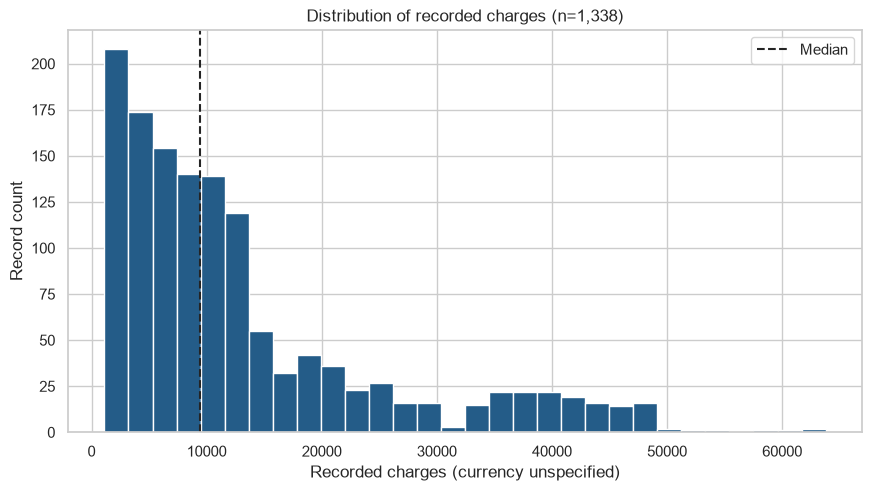

In [4]:
charges = cleaned_df.charges.to_numpy()
overall = pd.Series({"records": len(charges), "mean": np.mean(charges),
                     "median": np.median(charges), "sample_std": np.std(charges, ddof=1),
                     "q1": np.quantile(charges, .25), "q3": np.quantile(charges, .75),
                     "minimum": np.min(charges), "maximum": np.max(charges),
                     "arithmetic_total": np.sum(charges), "skew": cleaned_df.charges.skew()})
display(overall.to_frame("value"))
fig = chart(cleaned_df, "distribution")
fig.savefig(ROOT / "figures/distribution.png", dpi=150)
plt.show()

In [5]:
display(Markdown(
    f"Mean charges are **{overall['mean']:,.2f}**, while the median is "
    f"**{overall['median']:,.2f}**. The middle half runs from "
    f"{q1:,.2f} to {q3:,.2f}; sample standard deviation is "
    f"{overall['sample_std']:,.2f}. The longer upper tail and positive skew "
    f"({overall['skew']:.2f}) show why the average is above the median. "
    "Large charges are part of the observed distribution and have not been capped or deleted."
))

Mean charges are **13,270.42**, while the median is **9,382.03**. The middle half runs from 4,740.29 to 16,639.91; sample standard deviation is 12,110.01. The longer upper tail and positive skew (1.52) show why the average is above the median. Large charges are part of the observed distribution and have not been capped or deleted.

### Question 1: Smoking groups

The box plot shows the median and middle half of each group, with whiskers extending to the most extreme observations within 1.5 × IQR. Points beyond the whiskers remain in the analysis. Group sizes show the imbalance between categories.

,count,mean,median,std,minimum,maximum,q1,q3
smoker,,,,,,,,
no,1064,"8,434.27","7,345.41","5,993.78","1,121.87","36,910.61","3,986.44","11,362.89"
yes,274,"32,050.23","34,456.35","11,541.55","12,829.46","63,770.43","20,826.24","41,019.21"


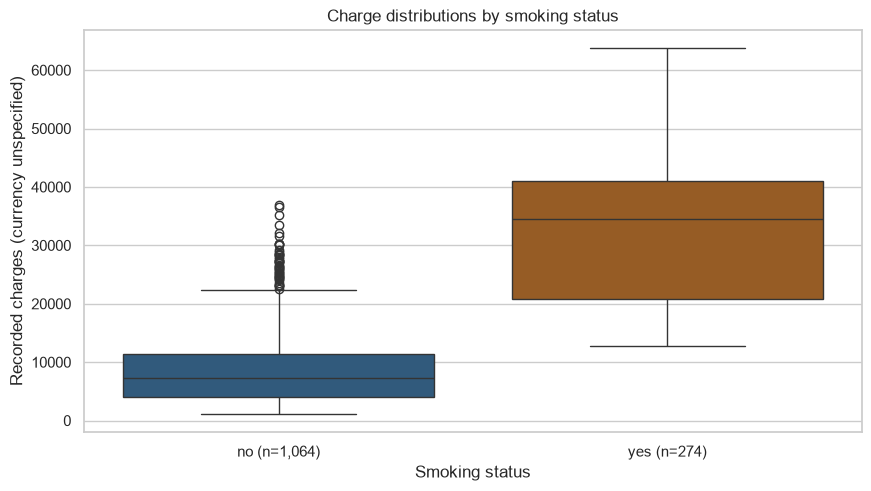

Smoking=yes has 274 records, compared with 1,064 for smoking=no. The mean difference is 23,615.96, with the yes-group mean 3.80 times the no-group mean. The medians also differ substantially. This answers the descriptive comparison, but it does not measure the effect of changing smoking behaviour. The groups may also differ in clinical conditions, age, BMI and other unrecorded factors.

In [6]:
smoking_summary = summary(cleaned_df, "smoker")
display(smoking_summary)
fig = chart(cleaned_df, "smoking")
fig.savefig(ROOT / "figures/smoking.png", dpi=150)
plt.show()
mean_gap = smoking_summary.loc["yes", "mean"] - smoking_summary.loc["no", "mean"]
mean_ratio = smoking_summary.loc["yes", "mean"] / smoking_summary.loc["no", "mean"]
display(Markdown(
    f"Smoking=yes has {smoking_summary.loc['yes', 'count']:,.0f} records, compared with "
    f"{smoking_summary.loc['no', 'count']:,.0f} for smoking=no. The mean difference is "
    f"{mean_gap:,.2f}, with the yes-group mean {mean_ratio:.2f} times the no-group mean. "
    "The medians also differ substantially. This answers the descriptive comparison, "
    "but it does not measure the effect of changing smoking behaviour. The groups may "
    "also differ in clinical conditions, age, BMI and other unrecorded factors."
))

### Question 2: Age, BMI and charges

Scatter plots keep individual observations visible. Smoking groups have both distinct colours and marker shapes. The correlations use age, BMI, covered dependants and charges only. Pearson correlation summarises linear association, so a weak overall value can hide distinct group patterns.

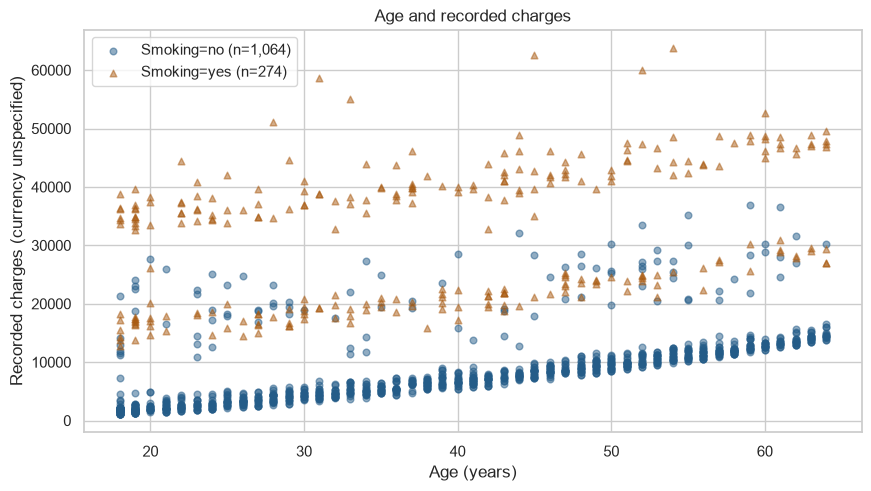

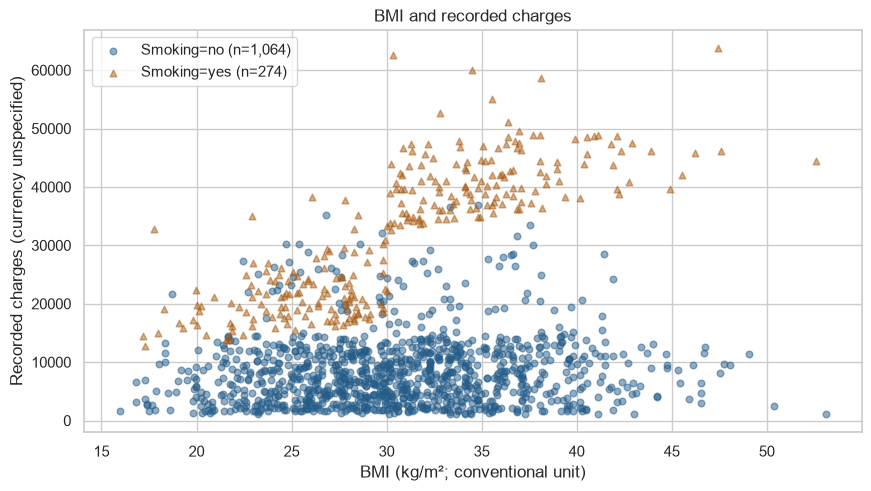

In [7]:
for kind in ["age", "bmi"]:
    fig = chart(cleaned_df, kind)
    fig.savefig(ROOT / f"figures/{kind}.png", dpi=150)
    plt.show()

,age,bmi,children,charges
age,1.00,0.11,0.04,0.30
bmi,0.11,1.00,0.01,0.20
children,0.04,0.01,1.00,0.07
charges,0.30,0.20,0.07,1.00


,age,bmi
smoker,,
no,0.63,0.08
yes,0.37,0.81


count      mean    median       std   minimum   maximum  \
age_band smoker                                                            
18-29    no        331  4,418.57  2,709.11  5,262.57  1,121.87 27,724.29   
         yes        86 27,518.04 33,604.25 10,359.84 12,829.46 51,194.56   
30-44    no        301  6,945.33  6,250.44  3,834.99  3,260.20 32,108.66   
         yes        91 30,833.99 35,491.64 11,027.66 15,820.70 58,571.07   
45-59    no        345 11,871.67 10,601.41  4,986.59  7,147.10 36,910.61   
         yes        70 35,889.87 40,847.36 11,446.78 21,098.55 63,770.43   
60-64    no         87 15,232.71 13,831.12  4,799.46 12,142.58 36,580.28   
         yes        27 40,630.70 46,599.11  9,478.84 26,926.51 52,590.83   

                       q1        q3  
age_band smoker                      
18-29    no      1,941.05  3,915.94  
         yes    17,082.13 36,143.26  
30-44    no      5,116.50  7,228.22  
         yes    19,881.40 39,854.11  
45-59    no      9,283.56 11,931.13  
         yes    24,425.28 44,246.23  
60-64    no     13,143.60 14,450.84  
         yes    29,236.17 47,665.96

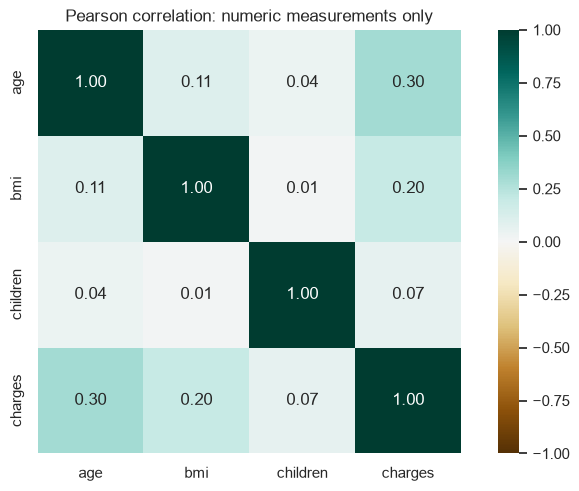

Across the full sample, age and charges have a Pearson correlation of 0.299; BMI and charges have a correlation of 0.198. Within smoking=yes, BMI's correlation is 0.806, compared with 0.084 within smoking=no. The plots and within-group calculations suggest that an overall correlation alone misses part of the pattern. These are observed associations; no clinical mechanism or causal effect has been tested.

In [8]:
correlations = cleaned_df[NUMERIC].corr()
display(correlations)
within_smoking = pd.DataFrame({
    group: part[["age", "bmi", "charges"]].corr()["charges"].drop("charges")
    for group, part in cleaned_df.groupby("smoker", observed=True)
}).T
within_smoking.index.name = "smoker"
display(within_smoking)
display(summary(cleaned_df, ["age_band", "smoker"]))
fig = chart(cleaned_df, "correlation")
fig.savefig(ROOT / "figures/correlation.png", dpi=150)
plt.show()
display(Markdown(
    f"Across the full sample, age and charges have a Pearson correlation of "
    f"{correlations.loc['age', 'charges']:.3f}; BMI and charges have a correlation of "
    f"{correlations.loc['bmi', 'charges']:.3f}. Within smoking=yes, BMI's correlation is "
    f"{within_smoking.loc['yes', 'bmi']:.3f}, compared with "
    f"{within_smoking.loc['no', 'bmi']:.3f} within smoking=no. "
    "The plots and within-group calculations suggest that an overall correlation alone "
    "misses part of the pattern. These are observed associations; no clinical mechanism "
    "or causal effect has been tested."
))

### Question 3: Regions and population mix

The grouped bars start at zero and display both mean and median. These are source categories, not a precise geographic map. Coordinates and confirmed region boundaries are unavailable. The second table compares smoking groups within each region rather than treating the regional average as a like-for-like comparison.

,count,mean,median,std,minimum,maximum,q1,q3
region,,,,,,,,
northeast,324,"13,406.38","10,057.65","11,255.80","1,694.80","58,571.07","5,194.32","16,687.36"
northwest,325,"12,417.58","8,965.80","11,072.28","1,621.34","60,021.40","4,719.74","14,711.74"
southeast,364,"14,735.41","9,294.13","13,971.10","1,121.87","63,770.43","4,440.89","19,526.29"
southwest,325,"12,346.94","8,798.59","11,557.18","1,241.57","52,590.83","4,751.07","13,462.52"


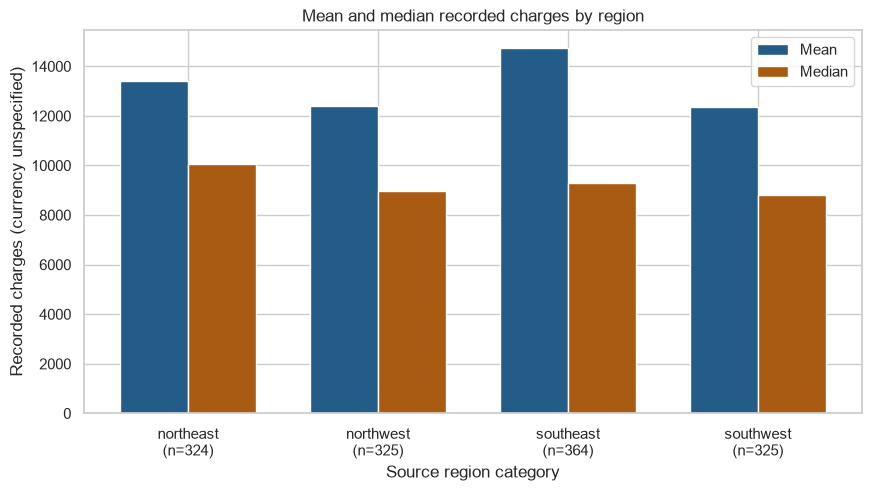

count      mean    median       std   minimum   maximum  \
region    smoker                                                            
northeast no        257  9,165.53  8,342.91  6,157.20  1,694.80 32,108.66   
          yes        67 29,673.54 28,101.33 11,589.56 12,829.46 58,571.07   
northwest no        267  8,556.46  7,256.72  6,128.55  1,621.34 33,471.97   
          yes        58 30,192.00 27,489.00 11,413.83 14,711.74 60,021.40   
southeast no        273  8,032.22  6,652.53  6,137.33  1,121.87 36,580.28   
          yes        91 34,845.00 37,484.45 11,324.77 16,577.78 63,770.43   
southwest no        267  8,019.28  7,348.14  5,489.51  1,241.57 36,910.61   
          yes        58 32,269.06 35,165.26 11,270.28 13,844.51 52,590.83   

                        q1        q3  
region    smoker                      
northeast no      4,438.26 11,938.26  
          yes    19,881.40 39,576.95  
northwest no      4,161.60 11,354.94  
          yes    20,834.13 39,918.95  
southeast no      3,471.41 10,982.50  
          yes    23,155.11 43,391.86  
southwest no      3,947.03 11,017.99  
          yes    20,396.04 39,809.29

,smoking_yes_percent
region,
northeast,20.68
northwest,17.85
southeast,25.00
southwest,17.85


,mean_at_common_smoking_mix
region,
northeast,"13,365.23"
northwest,"12,987.06"
southeast,"13,523.02"
southwest,"12,985.23"


In [9]:
region_summary = summary(cleaned_df, "region")
region_smoking = summary(cleaned_df, ["region", "smoker"])
display(region_summary)
fig = chart(cleaned_df, "region")
fig.savefig(ROOT / "figures/region.png", dpi=150)
plt.show()
display(region_smoking)
smoker_share = cleaned_df.assign(smoking_yes=cleaned_df.smoker.eq("yes")).groupby(
    "region").smoking_yes.mean().mul(100)
display(smoker_share.to_frame("smoking_yes_percent"))
# A common smoking mix is a descriptive sensitivity check, not full risk adjustment.
common_mix = cleaned_df.smoker.value_counts(normalize=True)
region_means = cleaned_df.groupby(["region", "smoker"]).charges.mean().unstack()
standardised = region_means.mul(common_mix, axis=1).sum(axis=1)
display(standardised.to_frame("mean_at_common_smoking_mix"))
assert region_summary["count"].sum() == len(cleaned_df)
assert region_smoking["count"].sum() == len(cleaned_df)
assert np.isclose(np.average(smoking_summary["mean"], weights=smoking_summary["count"]),
                  cleaned_df.charges.mean())

In [10]:
highest = region_summary["mean"].idxmax()
lowest = region_summary["mean"].idxmin()
display(Markdown(
    f"The highest overall regional mean is in {highest} "
    f"({region_summary.loc[highest, 'mean']:,.2f}); the lowest is in {lowest} "
    f"({region_summary.loc[lowest, 'mean']:,.2f}). "
    f"Smoking=yes makes up {smoker_share.loc['southeast']:.1f}% of southeast records. "
    "Southeast has the highest mean within smoking=yes but does not have the highest "
    "mean within smoking=no. A single regional ranking therefore hides different patterns. "
    "The common-mix calculation holds only the smoking-category proportions constant. "
    "It is a descriptive comparison and still leaves age, BMI, clinical needs and other "
    "possible confounders uncontrolled. The question is answered descriptively, while "
    "the reasons for the differences remain unresolved."
))
for name, table in [("smoking", smoking_summary), ("regions", region_summary),
                    ("region_smoking", region_smoking), ("within_smoking_correlations", within_smoking)]:
    table.to_csv(ROOT / f"evidence/{name}_summary.csv")

The highest overall regional mean is in southeast (14,735.41); the lowest is in southwest (12,346.94). Smoking=yes makes up 25.0% of southeast records. Southeast has the highest mean within smoking=yes but does not have the highest mean within smoking=no. A single regional ranking therefore hides different patterns. The common-mix calculation holds only the smoking-category proportions constant. It is a descriptive comparison and still leaves age, BMI, clinical needs and other possible confounders uncontrolled. The question is answered descriptively, while the reasons for the differences remain unresolved.

### Selection and independent calculation checks (2.1)

This example uses .loc, a Boolean condition and column selection. An independent standard-library calculation checks the overall and smoking-group means directly from the raw CSV, rather than trusting two outputs that share the same pandas function.

In [11]:
display(cleaned_df.loc[(cleaned_df.age >= 60) & cleaned_df.smoker.eq("no"),
                        ["age", "bmi", "smoker", "region", "charges"]].head())
import csv
from statistics import mean, median
with RAW.open(newline="") as handle:
    records = list(csv.DictReader(handle))
raw_charges = [float(row["charges"]) for row in records]
assert np.isclose(mean(raw_charges), cleaned_df.charges.mean())
assert np.isclose(median(raw_charges), cleaned_df.charges.median())
for group in ["no", "yes"]:
    values = [float(row["charges"]) for row in records if row["smoker"] == group]
    assert len(values) == smoking_summary.loc[group, "count"]
    assert np.isclose(mean(values), smoking_summary.loc[group, "mean"])
print("Independent raw-CSV mean, median and smoking-group checks passed.")

,age,bmi,smoker,region,charges
9,60,25.84,no,northwest,"28,923.14"
20,60,36.01,no,northeast,"13,228.85"
26,63,23.09,no,northeast,"14,451.84"
33,63,28.31,no,northwest,"13,770.10"
36,62,32.97,no,northwest,"15,612.19"


Independent raw-CSV mean, median and smoking-group checks passed.


### Code review and improvements (2.2)

**Correction 1: duplicated() arguments.** An initial inspection used `raw.duplicated(False)`. This failed with a KeyError because the first positional argument is the subset of columns, not the keep option. The corrected expression is `raw.duplicated(keep=False)`. The saved inspection now shows both matching rows and separately reports one repeated row after the first. This is an actual error encountered during preparation, not a fabricated earlier version. The test checks for two displayed matches and one repeat.

**Improvement 2: repeat-row policy.** Automatic `raw.drop_duplicates()` was considered as a cleaning option. It was not adopted as the main dataset because no identifier establishes that the matching records refer to one person. The revised approach preserves all rows and reports a sensitivity mean with the repeat removed. Row counts, total charges and the raw file hash reconcile after saving. Reliability is improved through an explicit assumption, rather than by claiming the matching rows have been resolved.

**Improvement 3: averages and denominators.** A region-only mean is useful but incomplete. The revised analysis adds medians, spread, group counts, region-by-smoking summaries and a common-smoking-mix sensitivity calculation. Counts reconcile to the original 1,338 rows. A test contrasts the weighted smoking-group mean with the whole-sample mean; an unweighted average of group means would give a different and inappropriate result for this imbalanced sample.

**Improvement 4: filtering and repeated plotting.** The dashboard uses explicit .isin conditions, so clearing a filter means no records. It stops before calculating empty-selection means. Reusable summary, narrative and chart functions avoid inconsistent copies of the same calculation. The narrative is recalculated from the selection, preventing the full-sample story from being displayed as if it described a subgroup. Automated tests exercise full, partial and empty selections.

Function names describe their purpose, docstrings explain intent, and formatting and linting are checked with Ruff. Numeric validation raises a clear error rather than silently coercing bad values to missing. The dashboard catches expected file/value errors and gives a useful message. No performance improvement is claimed because speed was not benchmarked.

Version control records separate milestones for source acquisition, the validated ETL, notebook evidence, dashboard/testing, and final delivery records. `git log --oneline` and `evidence/git_history.txt` show the actual history. There is no claim that these commits represent weeks of personal development. See `evidence/testing.md` for executed checks and any delivery gaps.

## Task 3: AI use, storytelling and evaluation (3.1-3.3)
### AI use record (3.1)

The tool used is OpenAI Codex. It suits this task because it can work across Python files, notebook explanations and dashboard code, then run the resulting checks. Its output can still contain wrong arguments, unjustified assumptions or polished explanations of incorrect calculations.

The user requested completion of all tasks with natural wording and minimal formatting. The assistant's initial decision was to read the brief and flag unverifiable personal evidence. After inspecting the actual CSV, the assistant reported 1,338 rows, seven fields, no missing values and one repeat, and proposed retaining the repeated row because there is no person ID. That suggestion was adopted in the code and checked through counts, source hashing and the duplicate sensitivity calculation.

The positional duplicated() mistake described above demonstrates why AI-generated code needs execution. The correction was accepted after the keyword-based selection returned the expected matching rows. Proposed transformations such as imputation, arbitrary category encoding and removing all high charges were not adopted because they would not solve an evidenced problem. These are recorded decisions, not attributed to an invented student conversation.

The complete project is AI-assisted, including the business discussion, code and narrative. The student must review it and decide what to retain. The written explanation is a draft for that review, rather than evidence that the student personally performed every development step. `evidence/ai_use.md` retains the prompt, generated narrative draft, revisions and numerical checks.

### Verified management narrative (3.2)

The first AI-generated draft is retained in the evidence record. It is revised here to specify the currency limitation, include group sizes and avoid turning the smoking association into a causal claim. The same final narrative function runs in the dashboard on the current filtered records.

In [12]:
final_story = narrative(cleaned_df)
display(Markdown(final_story))
(ROOT / "evidence/management_narrative.txt").write_text(final_story + chr(10))
assert f"{cleaned_df.charges.mean():,.2f}" in final_story
assert f"{cleaned_df.charges.median():,.2f}" in final_story
assert f"{smoking_summary.loc['yes', 'mean']:,.2f}" in final_story
assert f"{smoking_summary.loc['no', 'mean']:,.2f}" in final_story
print("Narrative numbers agree with the executed analysis.")

This selection contains 1,338 records. Mean recorded charges are 13,270.42, compared with a median of 9,382.03 (source currency unspecified). The mean is 32,050.23 for smoking=yes (n=274) and 8,434.27 for smoking=no (n=1,064). Use these differences to guide further investigation and scenario planning. They do not establish causes, future costs or suitable prices for individuals. The source does not confirm observation dates, currency or sampling coverage.

Narrative numbers agree with the executed analysis.


### Evaluate outcomes and alternatives (3.3)

The three questions were answered as descriptions of the downloaded records. Smoking groups differ substantially in level and spread. Age and BMI show different associations with charges, and the smoking-group views add detail that an overall correlation misses. Regional means and medians differ, while the within-smoking summaries show why a single regional ranking can be misleading. None of these results explains the underlying causes or establishes current costs for a wider population.

The work followed extraction, profiling, validation, transformation, CSV reload checks, summaries, charts and communication. Keeping the raw file and using the same functions in the notebook and dashboard makes that path easier to check. The most useful cleaning decision was to avoid making unnecessary changes: completeness did not require imputation and high charges were not automatically errors.

A bar chart of mean charges alone would be simpler to read, but it hides skew and spread. Pairing the mean with the median and a box plot gives a more complete picture at the cost of needing a short explanation of quartiles. A log-scale scatter plot is a reasonable alternative when low charges are compressed by the high values; the present original-scale plot keeps monetary differences directly readable. Pearson correlation is compact but assumes a linear summary; a rank-based Spearman comparison could be a useful follow-up if the question concerned monotonic ordering. No hypothesis test is needed merely to describe this sample, and no p-value would repair an unknown sampling frame.

The observation dates and collection method are unavailable. The 2023 upload date is not the date of medical care. Accuracy against clinical or financial records cannot be established, and the dataset cannot be treated as representative of a particular country or today's insured population. Coverage is limited to recorded ages 18-64 and the supplied binary categories. The smoking groups are imbalanced and some filtered groups are much smaller. Unknown diagnoses, treatment intensity, benefit design and access to services can confound comparisons. Charges may not equal payments or premiums.

AI can suggest plausible wording faster than it can establish that the wording is true. Here, actual code execution, independent CSV calculations and narrative checks reduce calculation risks, but they do not validate missing provenance or clinical explanations. The student still needs to understand the choices and adapt the draft to their own understanding.

A justified next step would be to obtain permissioned, dated claims and enrolment data with a confirmed currency and clear charge/payment definitions. Membership exposure would allow comparable per-person-period measures. Clinical information could support more meaningful case-mix comparisons. Any forecasting would then be evaluated on later data against a baseline and checked for subgroup error. Until then, the appropriate recommendation is further investigation and scenario discussion, rather than a numeric live-budget recommendation or an individual insurance decision.

## Task 4: Data management (4.1 and 4.2)
### Data dictionary (4.1)

Types below describe the cleaned dataset in memory; CSV does not preserve pandas category metadata. Source wording is not treated as a clinical measurement specification.

| Field | Type | Meaning and units |
| --- | --- | --- |
| age | int64 | Insured person's age; interpreted as whole years. Observed range 18-64. |
| sex | string category | Source labels female/male; publisher describes these as gender. Collection definition unavailable. |
| bmi | float64 | Body mass index; conventionally kg/m², but source does not explicitly confirm units. |
| children | int64 | Source describes number of dependants covered. A count, not a verified household size. |
| smoker | string category | Source yes/no smoking label; definition and reference date unavailable. |
| region | string category | northeast/northwest/southeast/southwest. Country and exact boundaries unconfirmed. |
| charges | float64 | Recorded medical insurance costs incurred, per source description; currency, period and billed/paid status unconfirmed. |
| age_band | ordered category | Derived [18,30), [30,45), [45,60), [60,65), labelled 18-29, 30-44, 45-59, 60-64. |

### Lineage and storage

The Kaggle ZIP supplies `data/raw/insurance.csv`. Its hash is recorded before transformations. `prepare_data()` creates a separate cleaned DataFrame, validates source fields and adds age_band. `save_and_check()` writes `data/processed/insurance_cleaned.csv`, reloads it and compares values. Summaries are saved under evidence and plots under figures. The notebook presents those outputs, while app.py reads the cleaned file and uses the same tested summary/filter/chart functions.

CSV is appropriate here because the sample is small, easy to inspect and portable. Separate raw and processed folders make transformations visible. CSV does not enforce types, relationships or permissions, so the Python validation and documented schema are important. A relational database such as PostgreSQL would be a better choice for growing claims and membership tables: keys and constraints could support integrity, roles could control access and transactions could coordinate updates. That would add administration and migration work with little benefit for a single static teaching file. A database would not fix incorrect source data automatically.

### Quality dimensions and actions (4.1 and 4.2)

Completeness is measured by null counts across all seven source columns, with zero missing cells in this download. Consistency is measured by category membership and the normalisation change log, which records zero changed labels. Validity is checked through finite numeric values, non-negative charges/dependants, positive BMI, whole-number counts and the age-band scope. These checks pass. The notebook reports charge outliers separately and retains them. Uniqueness cannot be confirmed without an ID: one row repeats, but neither row is excluded. Accuracy cannot be established against an authoritative record, and timeliness cannot be assessed without observation dates. These are limitations rather than checks marked as passed.

The workflow stops on schema changes, missing values, invalid categories, non-numeric measurements or failed reload equality. The next action would be to inspect the source, document the cause and revise rules or obtain a corrected file; it would not silently drop records. Plausibility flags and outliers require review. The present download has no BMI/dependant plausibility flags, so no such exclusions are applied. Repeatability is supported by relative project paths, a preserved source snapshot, explicit dependencies, meaningful commits, tests and a notebook executed from a fresh kernel.

### Privacy, security and ethics (4.2)

The file has no direct identifier, but that alone does not prove full anonymisation. Age, region and health-related attributes should not be joined to other data to try to identify people. The dashboard shares aggregate findings and no additional personal information. Real operational work should minimise fields, restrict raw claims to authorised staff, use secure transfer and storage, keep credentials outside Git and log access. A retention schedule should follow the legitimate purpose and organisational requirements rather than keeping identifiable claims indefinitely. For this public learning project, retain the source and evidence through marking and any appeal period, then review local copies and published access with the college's policy; no fixed legal retention period is invented.

ICO guidance explains that personal data revealing health information can be special category data [6]. If identifiable UK health data were added, a lawful basis and applicable special-category condition would need to be established with the organisation's data-protection lead. This statement does not establish that the present public file is identifiable, nor does it substitute for legal advice about a real insurer. CC0 addresses copyright permissions but does not erase privacy rights [7]. Public access by itself is not enough to assume unrestricted reuse.

HL7 FHIR is a standard for electronic exchange of healthcare information [8]. It could matter if a future project obtained structured clinical or claims resources from an operational system. This flat CSV is not a FHIR resource, so claiming FHIR compliance would be misleading. Clinical coding standards would likewise matter if diagnosis or procedure codes were present; they are not present here.

The source's limited category coverage and unknown sampling may hide or reinforce bias. The analysis does not rank people's worth, estimate treatment effectiveness or recommend denying coverage. A relationship involving smoking, sex, BMI or age is not enough to justify an individual pricing rule. Aggregate investigation should consider clinical context, fairness and applicable insurance rules before any operational use.

## Delivery and references

The repository README records setup, evidence locations and delivery status. The dashboard is implemented as a separate Streamlit application. Deployment and assessor access must be verified through a working remote link; a local run alone does not satisfy that requirement. `evidence/testing.md` records the actual status and checks.

References, accessed 27 October 2026:

1. willian oliveira. *Healthcare Insurance*, Kaggle, version 1. https://www.kaggle.com/datasets/willianoliveiragibin/healthcare-insurance . Source description, downloaded file and saved metadata.
2. AHRQ. *HCUP Overview*. https://hcup-us.ahrq.gov/overview.jsp . Cost, utilisation and outcomes research context.
3. CMS Measures Management System. *Risk Adjustment and Risk Stratification Overview*. https://mmshub.cms.gov/measure-lifecycle/measure-specification/risk-adjustment-overview . Grouping and case-mix comparison.
4. CMS. *Risk Adjustment*. https://www.cms.gov/priorities/innovation/key-concepts/risk-adjustment . Expense-estimation application.
5. AHRQ. *Making Adjustments to Health Care Quality Scores*. https://www.ahrq.gov/talkingquality/translate/scores/adjustment-scoring.html . Risk/severity and comparison limits.
6. ICO. *What is special category data?* https://ico.org.uk/for-organisations/uk-gdpr-guidance-and-resources/lawful-basis/special-category-data/what-is-special-category-data/ . Conditional discussion of identifiable health data.
7. Creative Commons. *CC0 1.0 Universal*. https://creativecommons.org/publicdomain/zero/1.0/ . Copyright waiver and remaining rights.
8. HL7. *FHIR Overview*. https://fhir.hl7.org/fhir/overview.html . Relevance of healthcare information exchange standards.

Original assignment: Unit_1_Healthcare_Insurance_Assignment_Brief_v5.pdf, issued 26 October 2026. The separate Code Institute handbook was referenced by the brief but was not supplied or claimed as independently reviewed. Project code was generated for this task with OpenAI Codex assistance; no external tutorial code was copied.